<a href="https://colab.research.google.com/github/HC-AIGroup/CS5330_F26/blob/main/module2/Guassian_VS_Mean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<>:55: SyntaxWarning: invalid escape sequence '\s'
<>:55: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2242/3802114522.py:55: SyntaxWarning: invalid escape sequence '\s'
  axes[2].set_title(f"Gaussian Filter {ksize} ($\sigma=1.5$)\nDistance-Weighted", fontsize=13)


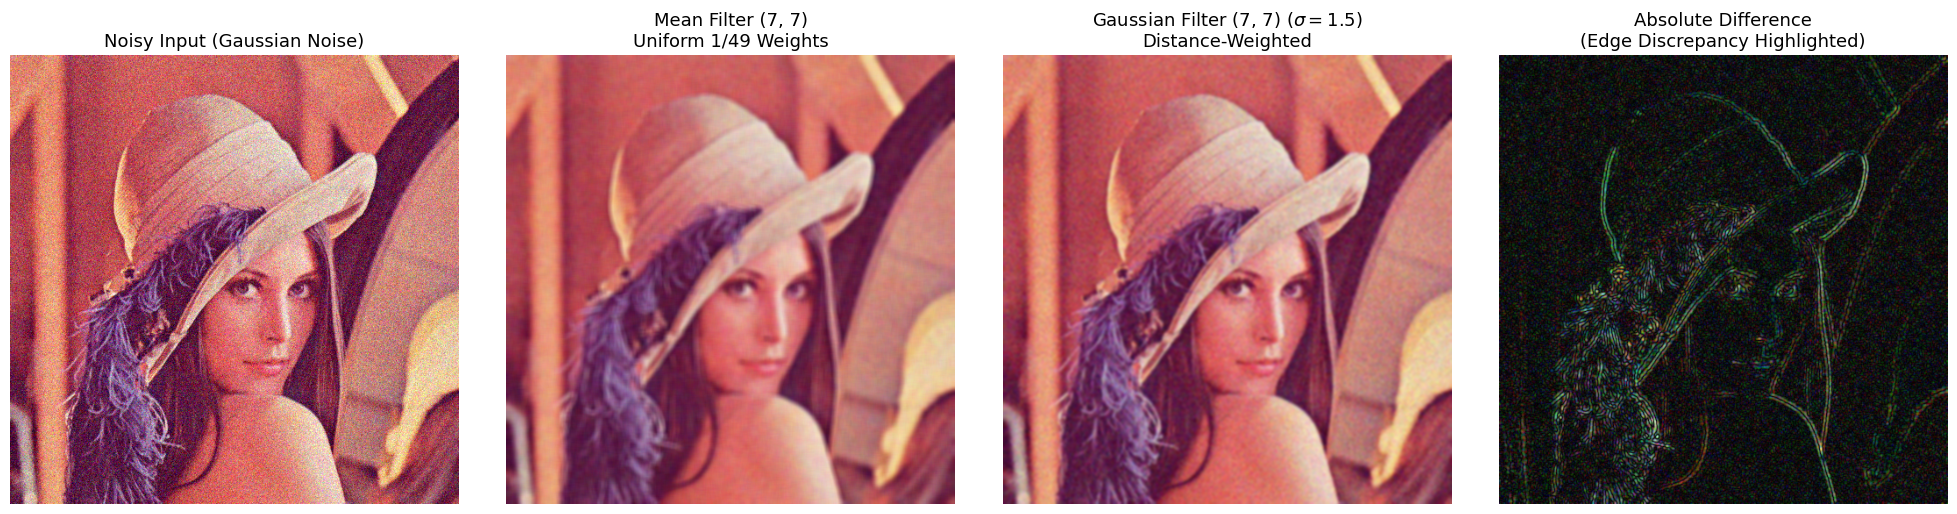

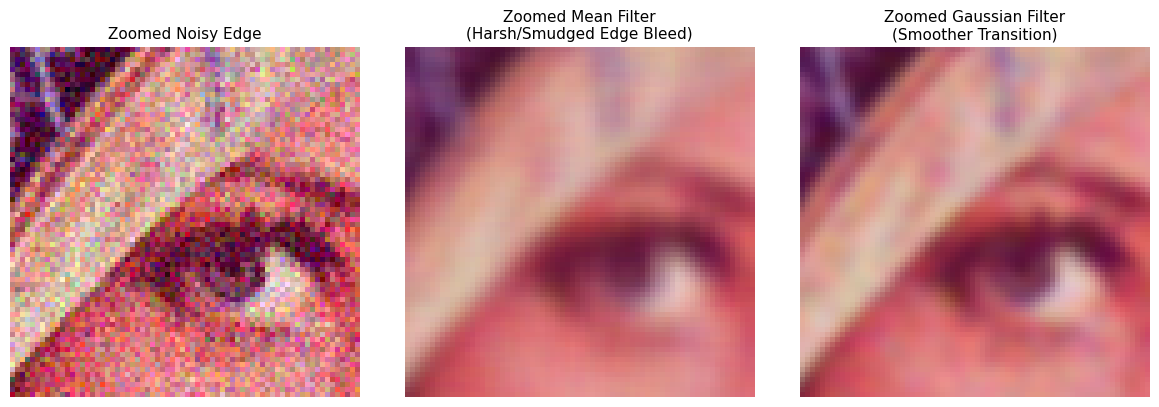

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# ---------------------------------------------------------
# Step 1: Load a Sample Image Directly via URL (or create synthetic)
# ---------------------------------------------------------
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
image_path = "sample_image.jpg"

try:
    urllib.request.urlretrieve(url, image_path)
    img_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
except Exception:
    # Fallback: Create a clean geometric synthetic image if offline/blocked
    img_rgb = np.zeros((300, 300, 3), dtype=np.uint8)
    img_rgb[40:260, 40:260] = [200, 200, 200]
    cv2.circle(img_rgb, (150, 150), 60, (20, 40, 220), -1)
    cv2.putText(img_rgb, "TEST", (90, 165), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (255, 255, 255), 3)

# ---------------------------------------------------------
# Step 2: Add Additive Gaussian Noise
# ---------------------------------------------------------
# Generating zero-mean Gaussian noise (mean=0, std=25)
noise = np.random.normal(0, 25, img_rgb.shape).astype(np.float32)
noisy_img = np.clip(img_rgb.astype(np.float32) + noise, 0, 255).astype(np.uint8)

# ---------------------------------------------------------
# Step 3: Apply Filters (Matching Kernel Window: 7x7)
# ---------------------------------------------------------
ksize = (7, 7)

# 1. Mean (Box) Filter: Uniform weights across the window
mean_filtered = cv2.blur(noisy_img, ksize)

# 2. Gaussian Filter: Distance-weighted bell curve decay
gaussian_filtered = cv2.GaussianBlur(noisy_img, ksize, sigmaX=1.5)

# ---------------------------------------------------------
# Step 4: Visual & Qualitative Comparison
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(noisy_img)
axes[0].set_title("Noisy Input (Gaussian Noise)", fontsize=13)
axes[0].axis("off")

axes[1].imshow(mean_filtered)
axes[1].set_title(f"Mean Filter {ksize}\nUniform 1/{ksize[0]*ksize[1]} Weights", fontsize=13)
axes[1].axis("off")

axes[2].imshow(gaussian_filtered)
axes[2].set_title(f"Gaussian Filter {ksize} ($\sigma=1.5$)\nDistance-Weighted", fontsize=13)
axes[2].axis("off")

# Absolute difference highlighting edge degradation in the Mean filter vs. Gaussian
diff = cv2.absdiff(mean_filtered, gaussian_filtered)
# Amplify difference for clear visualization
diff_enhanced = cv2.normalize(diff, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)

axes[3].imshow(diff_enhanced, cmap="inferno")
axes[3].set_title("Absolute Difference\n(Edge Discrepancy Highlighted)", fontsize=13)
axes[3].axis("off")

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Step 5: Zoom In on a Specific Edge Region to Inspect Bleed
# ---------------------------------------------------------
# Crop coordinates around the center
h, w, _ = img_rgb.shape
cy, cx = h // 2, w // 2
crop_slice = (slice(cy - 35, cy + 35), slice(cx - 35, cx + 35))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(noisy_img[crop_slice])
axes[0].set_title("Zoomed Noisy Edge", fontsize=11)
axes[0].axis("off")

axes[1].imshow(mean_filtered[crop_slice])
axes[1].set_title("Zoomed Mean Filter\n(Harsh/Smudged Edge Bleed)", fontsize=11)
axes[1].axis("off")

axes[2].imshow(gaussian_filtered[crop_slice])
axes[2].set_title("Zoomed Gaussian Filter\n(Smoother Transition)", fontsize=11)
axes[2].axis("off")

plt.tight_layout()
plt.show()

<>:55: SyntaxWarning: invalid escape sequence '\s'
<>:55: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2242/1911375855.py:55: SyntaxWarning: invalid escape sequence '\s'
  ax3.set_title("3. Gaussian Filter (15x15, $\sigma=2.5$)\n*Smooth Circular Softening*", fontsize=12)


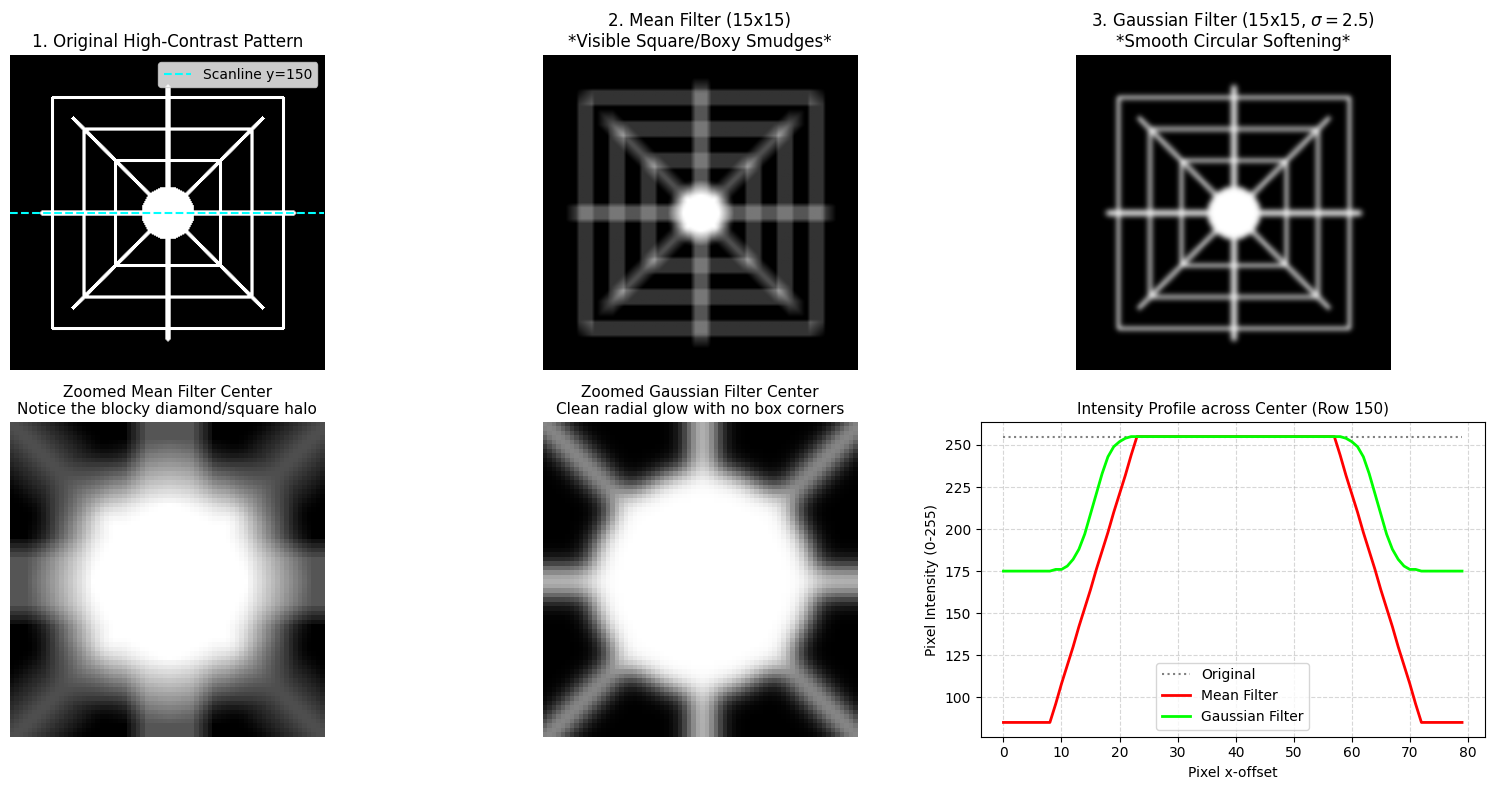

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 1. Create a High-Contrast Test Pattern: Crisp White Star on Pure Black
# -------------------------------------------------------------------------
img = np.zeros((300, 300), dtype=np.uint8)

# Draw fine concentric squares and high-frequency lines
cv2.rectangle(img, (40, 40), (260, 260), 255, 2)
cv2.rectangle(img, (70, 70), (230, 230), 255, 2)
cv2.rectangle(img, (100, 100), (200, 200), 255, 2)

# Draw an intense white 8-pointed star/cross in the middle
cv2.line(img, (150, 30), (150, 270), 255, 3)
cv2.line(img, (30, 150), (270, 150), 255, 3)
cv2.line(img, (60, 60), (240, 240), 255, 3)
cv2.line(img, (60, 240), (240, 60), 255, 3)
cv2.circle(img, (150, 150), 25, 255, -1)

# -------------------------------------------------------------------------
# 2. Apply a Large Filter Window (15x15) to Highlight Spatial Geometry
# -------------------------------------------------------------------------
ksize = (15, 15)

# Mean Filter: treats the 15x15 square uniformly
mean_filtered = cv2.blur(img, ksize)

# Gaussian Filter: weights by radial distance from center
gaussian_filtered = cv2.GaussianBlur(img, ksize, sigmaX=2.5)

# -------------------------------------------------------------------------
# 3. Visual Comparison & 1D Intensity Cross-Section
# -------------------------------------------------------------------------
fig = plt.figure(figsize=(16, 8))

# Image 1: Original Crisp Pattern
ax1 = fig.add_subplot(2, 3, 1)
ax1.imshow(img, cmap='gray')
ax1.axhline(150, color='cyan', linestyle='--', label='Scanline y=150')
ax1.set_title("1. Original High-Contrast Pattern", fontsize=12)
ax1.axis("off")
ax1.legend(loc="upper right")

# Image 2: Mean Filter Output (Notice square/boxy halo artifacts)
ax2 = fig.add_subplot(2, 3, 2)
ax2.imshow(mean_filtered, cmap='gray')
ax2.set_title("2. Mean Filter (15x15)\n*Visible Square/Boxy Smudges*", fontsize=12)
ax2.axis("off")

# Image 3: Gaussian Filter Output (Notice circular/isotropic natural falloff)
ax3 = fig.add_subplot(2, 3, 3)
ax3.imshow(gaussian_filtered, cmap='gray')
ax3.set_title("3. Gaussian Filter (15x15, $\sigma=2.5$)\n*Smooth Circular Softening*", fontsize=12)
ax3.axis("off")

# 4. Zoomed Comparison on a Single Vertex
crop = (slice(115, 185), slice(115, 185))

ax4 = fig.add_subplot(2, 3, 4)
ax4.imshow(mean_filtered[crop], cmap='gray')
ax4.set_title("Zoomed Mean Filter Center\nNotice the blocky diamond/square halo", fontsize=11)
ax4.axis("off")

ax5 = fig.add_subplot(2, 3, 5)
ax5.imshow(gaussian_filtered[crop], cmap='gray')
ax5.set_title("Zoomed Gaussian Filter Center\nClean radial glow with no box corners", fontsize=11)
ax5.axis("off")

# 5. 1D Intensity Profile across Row y=150
ax6 = fig.add_subplot(2, 3, 6)
ax6.plot(img[150, 110:190], label="Original", color="gray", linestyle=":")
ax6.plot(mean_filtered[150, 110:190], label="Mean Filter", color="red", linewidth=2)
ax6.plot(gaussian_filtered[150, 110:190], label="Gaussian Filter", color="lime", linewidth=2)
ax6.set_title("Intensity Profile across Center (Row 150)", fontsize=11)
ax6.set_xlabel("Pixel x-offset")
ax6.set_ylabel("Pixel Intensity (0-255)")
ax6.grid(True, linestyle="--", alpha=0.5)
ax6.legend()

plt.tight_layout()
plt.show()
